In [442]:
# all the imports 

In [443]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as py
from plotly.offline import iplot
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import confusion_matrix, classification_report , accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import roc_curve, auc
sns.set_theme()


In [444]:
#dataset size defination

In [445]:
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 200)

In [446]:
df = pd.read_csv(r"D:\Rohit\Parkinsons\Databases\park-database.csv")

In [447]:
df.head(200)

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.000070,0.00370,0.00554,0.01109,0.04374,0.426,0.02182,0.03130,0.02971,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.000080,0.00465,0.00696,0.01394,0.06134,0.626,0.03134,0.04518,0.04368,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.000090,0.00544,0.00781,0.01633,0.05233,0.482,0.02757,0.03858,0.03590,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.000090,0.00502,0.00698,0.01505,0.05492,0.517,0.02924,0.04005,0.03772,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.000110,0.00655,0.00908,0.01966,0.06425,0.584,0.03490,0.04825,0.04465,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
5,phon_R01_S01_6,120.552,131.162,113.787,0.00968,0.000080,0.00463,0.00750,0.01388,0.04701,0.456,0.02328,0.03526,0.03243,0.06985,0.01222,21.378,1,0.415564,0.825069,-4.242867,0.299111,2.187560,0.357775
6,phon_R01_S02_1,120.267,137.244,114.820,0.00333,0.000030,0.00155,0.00202,0.00466,0.01608,0.140,0.00779,0.00937,0.01351,0.02337,0.00607,24.886,1,0.596040,0.764112,-5.634322,0.257682,1.854785,0.211756
7,phon_R01_S02_2,107.332,113.840,104.315,0.00290,0.000030,0.00144,0.00182,0.00431,0.01567,0.134,0.00829,0.00946,0.01256,0.02487,0.00344,26.892,1,0.637420,0.763262,-6.167603,0.183721,2.064693,0.163755
8,phon_R01_S02_3,95.730,132.068,91.754,0.00551,0.000060,0.00293,0.00332,0.00880,0.02093,0.191,0.01073,0.01277,0.01717,0.03218,0.01070,21.812,1,0.615551,0.773587,-5.498678,0.327769,2.322511,0.231571
9,phon_R01_S02_4,95.056,120.103,91.226,0.00532,0.000060,0.00268,0.00332,0.00803,0.02838,0.255,0.01441,0.01725,0.02444,0.04324,0.01022,21.862,1,0.547037,0.798463,-5.011879,0.325996,2.432792,0.271362


In [448]:
#findin null

In [449]:
df.isnull().sum()

name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64

In [450]:
#finding depending variable

In [451]:
df.dtypes

name                    str
MDVP:Fo(Hz)         float64
MDVP:Fhi(Hz)        float64
MDVP:Flo(Hz)        float64
MDVP:Jitter(%)      float64
MDVP:Jitter(Abs)    float64
MDVP:RAP            float64
MDVP:PPQ            float64
Jitter:DDP          float64
MDVP:Shimmer        float64
MDVP:Shimmer(dB)    float64
Shimmer:APQ3        float64
Shimmer:APQ5        float64
MDVP:APQ            float64
Shimmer:DDA         float64
NHR                 float64
HNR                 float64
status                int64
RPDE                float64
DFA                 float64
spread1             float64
spread2             float64
D2                  float64
PPE                 float64
dtype: object

In [452]:
#data distribution

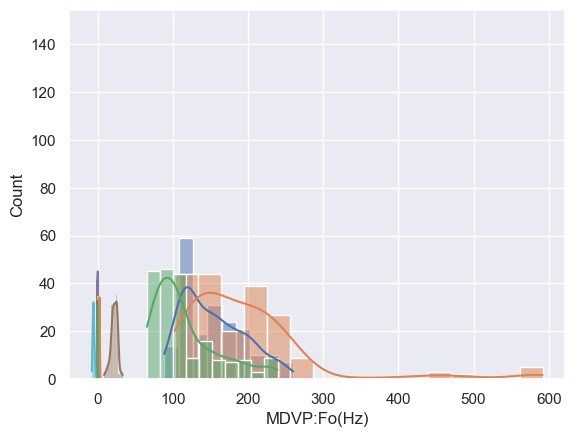

In [453]:
def displot(col):
    sns.histplot(df[col] , kde=True)
    plt.show

for i in list(df.columns)[1:]:
    displot(i)

In [454]:
#finding outliers

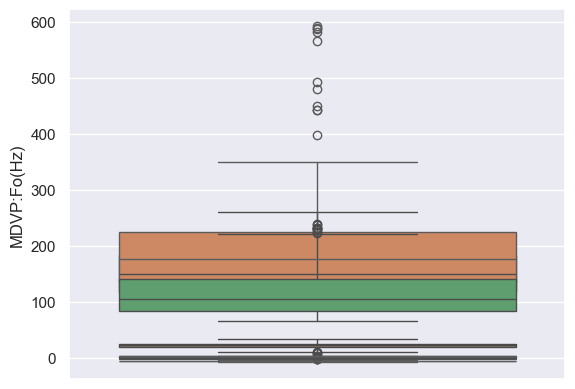

In [455]:
def boxplot(col):
    #plt.figure()
    sns.boxplot(df[col])
    plt.show

for i in list(df.columns)[1:]:
     boxplot(i)


In [456]:
#Finding Correlation

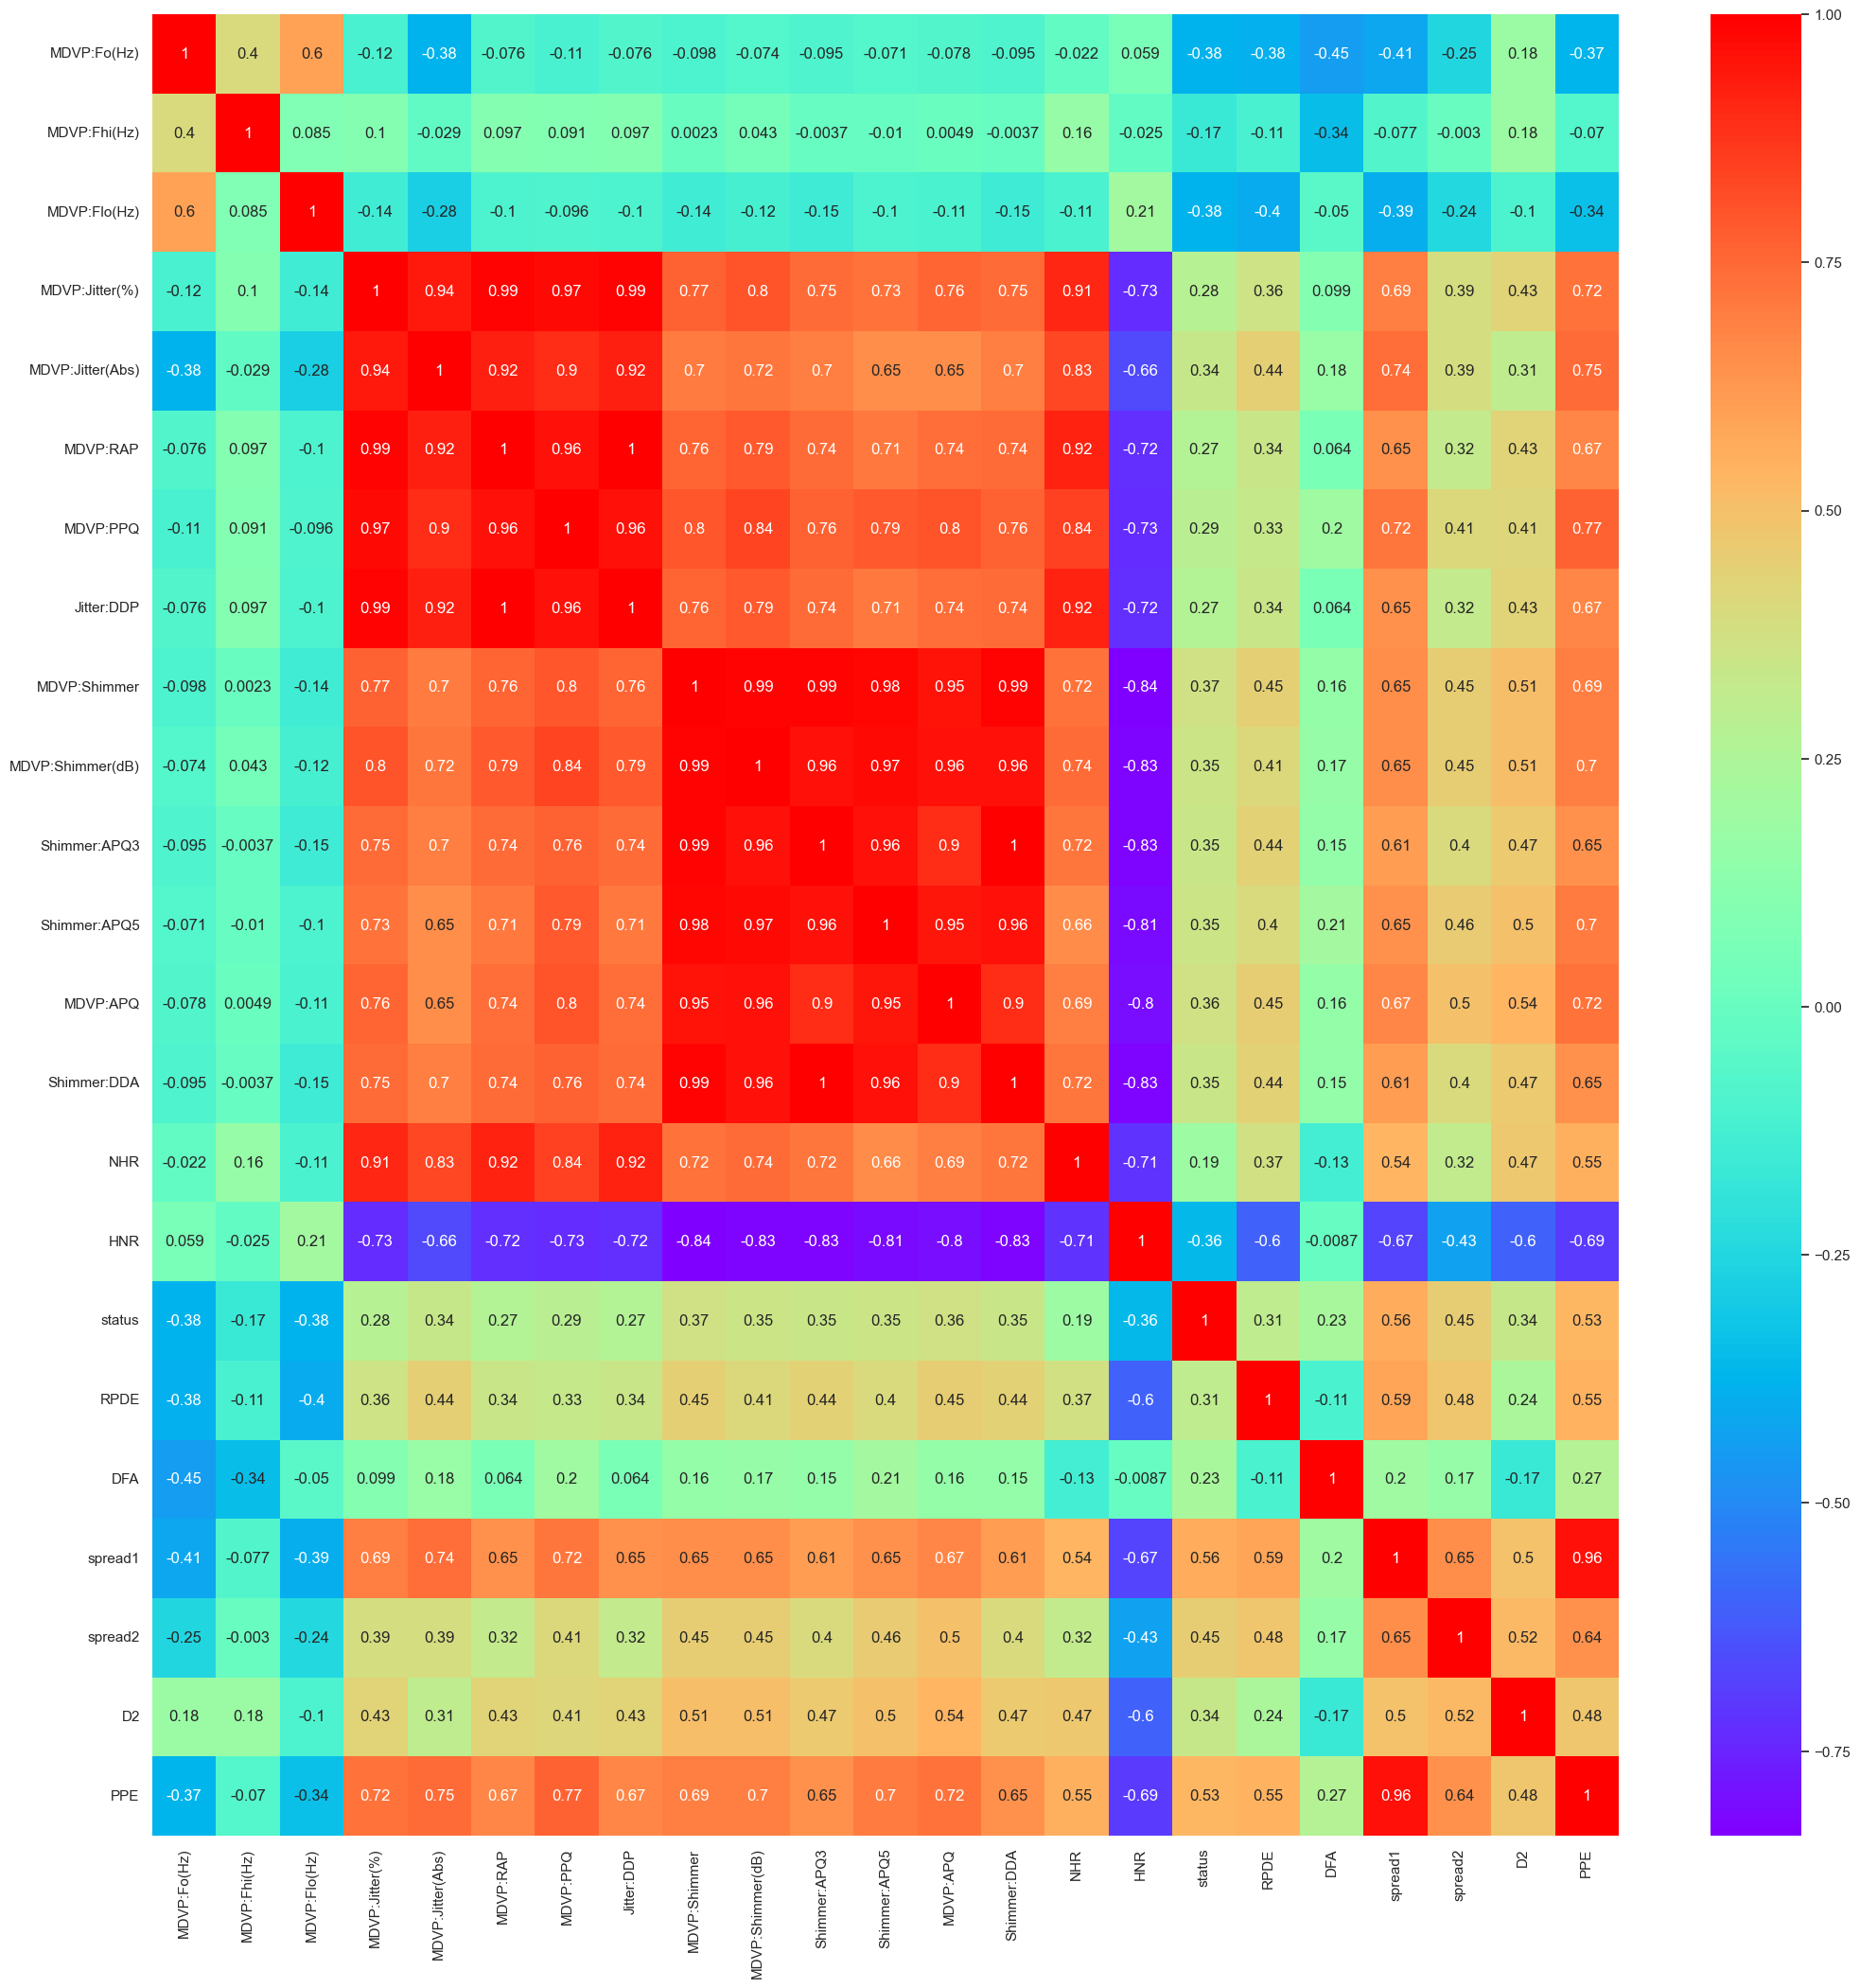

In [457]:

plt.figure(figsize=(25,25))
corr = df.drop(columns=['name']).corr()
sns.heatmap(corr, annot=True, cmap="rainbow")
plt.show()

In [458]:
# Dropping the Name and Status

In [459]:
x = df.drop(['status','name'],axis=1)
y = df['status']


In [460]:
#Checking New dataset 

In [461]:
x.head()


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,0.02182,0.03130,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,0.03134,0.04518,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,0.02757,0.03858,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,0.02924,0.04005,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,0.03490,0.04825,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [462]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: status, dtype: int64

In [463]:
# Balancing the dataset 

In [464]:
from imblearn.over_sampling import RandomOverSampler
randos = RandomOverSampler()
x_randos , y_randos = randos.fit_resample(x,y)
print("Y value cound ",y.value_counts())
print("Y RandomOverSampler value count ",y_randos.value_counts())

Y value cound  status
1    147
0     48
Name: count, dtype: int64
Y RandomOverSampler value count  status
1    147
0    147
Name: count, dtype: int64


In [465]:
#Feature Scaling

In [466]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler((-1,1))
x = scaler.fit_transform(x_randos)
y = y_randos
x.shape


(294, 22)

In [467]:
#EDA completed

In [468]:
#Applying PCA

In [469]:
from sklearn.decomposition import PCA
pca = PCA(.95)
x_pca = pca.fit_transform(x)
print(x.shape)
print(x_pca.shape)

(294, 22)
(294, 8)


In [470]:
#Checking PDA dataset

In [471]:
pca_df = pd.DataFrame(x_pca)
print(pca_df.head(300))

            0         1         2         3         4         5         6         7
0    1.245328 -0.461977  0.773575 -0.497672  0.176177 -0.118798  0.080974 -0.136726
1    2.008711  0.100774  1.095053 -0.058747  0.345118 -0.215219  0.133194 -0.273043
2    1.691767 -0.103744  1.156454 -0.194215  0.175617  0.025249  0.040254 -0.128625
3    1.833866 -0.074978  1.117779 -0.130413  0.317110 -0.021353  0.045581 -0.210268
4    2.216414  0.219202  1.304633 -0.359168 -0.081672 -0.020940 -0.067214 -0.512921
..        ...       ...       ...       ...       ...       ...       ...       ...
289 -1.215476  0.378323 -0.136144 -0.871840 -0.301483 -0.364365 -0.145952 -0.174144
290 -0.044906 -0.798492 -0.042109  0.439345 -0.092355  0.050031  0.078837  0.281130
291 -0.051464 -0.777461 -0.662803  0.313328 -0.356087  0.115812 -0.205167 -0.349363
292  0.157374 -0.719831 -0.431237  0.477282 -0.313157  0.087867 -0.229715 -0.123593
293 -1.077458  1.220470 -0.152104  0.748860 -0.152792  0.142506  0.151596  0

In [472]:
# Spliting the dataset , For Training and Testing

In [473]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x_pca, y , test_size = 0.2 , random_state=14)

In [474]:
#Checking the Splits 

In [475]:
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape:  {x_test.shape}")

x_train shape: (235, 8)
x_test shape:  (59, 8)


In [476]:
#Difference between train and test

In [477]:
df_x_train_pc1 = pd.DataFrame(x_train[:, 0], columns=['pc1'])
df_x_test_pc1 = pd.DataFrame(x_test[:, 0], columns=['pc1'])
print("--- Training Data (x_train)")
display(df_x_train_pc1.head(1)) 
print("\n--- Testing Data (x_test)")
display(df_x_test_pc1.head(1))

--- Training Data (x_train)


,pc1
0,-0.318983



--- Testing Data (x_test)


,pc1
0,-1.760351


In [478]:
#Building the Model


In [479]:
list_met= []
list_accuracy = []

In [480]:
#Model 1
#logistic Regression
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(C = 0.4 , max_iter=1000 ,solver='liblinear' ) #shift-tap
lr = classifier.fit(x_train, y_train)
#Prediction
y_pred = classifier.predict(x_test)
#Accuracy
accuracy_LR = accuracy_score(y_test,y_pred)

In [481]:
#Model 2
#Decision Tree
from sklearn.tree import DecisionTreeClassifier
classifier2 = DecisionTreeClassifier(random_state=14)
dt = classifier2.fit(x_train, y_train)
y_pred2 =  classifier2.predict(x_test)
#evaluation
accuracy_DT = accuracy_score(y_test,y_pred2)

In [482]:
#Model 3
#Ramdpm forest Gini
from sklearn.ensemble import RandomForestClassifier
classifier3 = RandomForestClassifier(random_state=14)
rfi = classifier3.fit(x_train,y_train)
#prediction
y_pred3 = classifier3.predict(x_test)
accuracy_RFI = accuracy_score(y_test,y_pred3)

In [483]:
#Model4
#Random Forest Entropy
classifier4 = RandomForestClassifier(criterion='entropy' , random_state=14)
rfe = classifier4.fit(x_train,y_train)
#predict
y_pred4= classifier4.predict(x_test)
#evaluation
accuracy_RFE = accuracy_score(y_test, y_pred4)

In [484]:
#Model5
#Support Vector
from sklearn.svm import SVC
model_svm= SVC(probability=True)
svm = model_svm.fit(x_train, y_train)
#prediction
y_pred5 = model_svm.predict(x_test)
accuracy_SVM = accuracy_score(y_test,y_pred5)

In [485]:
#Model 6
#KNN
from sklearn.neighbors import KNeighborsClassifier
model_knn = KNeighborsClassifier()
knn = model_knn.fit(x_train , y_train)
#prediction
pred_knn = model_knn.predict(x_test)
#evaluation
accuracy_knn = accuracy_score(y_test,pred_knn)

In [486]:
#model 7
#Gaussian
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb = gnb.fit(x_train , y_train)
#prediction
pred_gnb = gnb.predict(x_test)
#evaluation
accuracy_gnb = accuracy_score(y_test , pred_gnb)

In [487]:
#model 8
#bernoull
from sklearn.naive_bayes import BernoulliNB
bnb = BernoulliNB()
bnb =  bnb.fit(x_train,y_train)
#prediction
pred_bnb = bnb.predict(x_test)
#evaluation
accuracy_BNB = accuracy_score(y_test , pred_bnb)


In [488]:
#Voting

In [489]:
from sklearn.ensemble import VotingClassifier
evc = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('DT', dt),
        ('RandomForest', rfi),
        ('Entropy', rfe),
        ('SVM', svm),
        ('KNN', knn), 
        ('GaussianNB', gnb),
        ('BernoulliNB', bnb) 
    ],
        voting="soft",
        flatten_transform=True
   
    
)


In [490]:
#Accuracy Score and Graph

          Method Used :   Accuracy : 
0    Logistic Regression     0.779661
1          Decision Tree     0.932203
2     RandomForest Gini      0.966102
3   RandomForest Entropy     0.983051
4         Support Vector     0.966102
5     Nearest Neighbours     0.966102
6               Gaussian     0.915254
7              Bernouli      0.728814
8                 Voting     0.966102


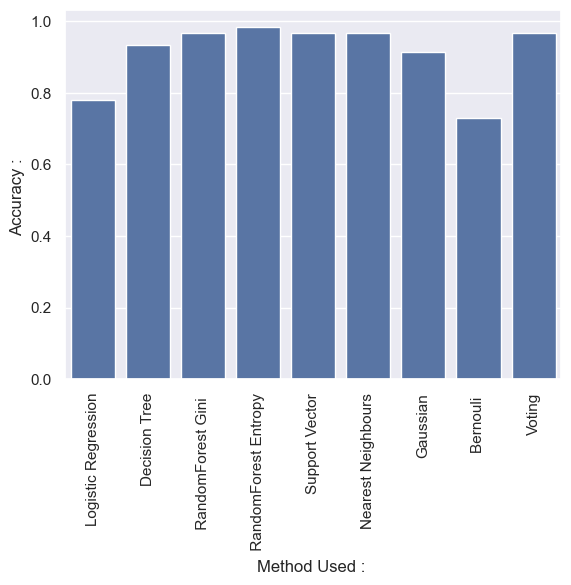

In [491]:
model_evc = evc.fit(x_train,y_train)
#prediction
pred_evc = evc.predict(x_test)
#evaluation
accuracy_evc = accuracy_score(y_test , pred_evc)

list1 = ["Logistic Regression" , "Decision Tree" , " RandomForest Gini " , " RandomForest Entropy" , "Support Vector" , "Nearest Neighbours" , "Gaussian" , "Bernouli " , "Voting"]

list2 = [accuracy_LR,accuracy_DT,accuracy_RFI,accuracy_RFE,accuracy_SVM,accuracy_knn,accuracy_gnb,accuracy_BNB,accuracy_evc]

list3 = [classifier,classifier2,classifier3,classifier4,model_svm,model_knn,gnb,bnb,model_evc]

df_accuracy = pd.DataFrame({"Method Used : ": list1, "Accuracy : ": list2})
print(df_accuracy)

charts = sns.barplot( x ="Method Used : ", y="Accuracy : ", data=df_accuracy)
charts.tick_params(axis='x', rotation=90)
plt.show()

In [492]:
#Comparing two models


In [493]:
#RandomForest Entropy
y_pred4_train= classifier4.predict(x_train)
y_pred4_test= classifier4.predict(x_test)
#KNN
pred_knn_train = model_knn.predict(x_train)
pred_knn_test = model_knn.predict(x_test)

print(confusion_matrix(y_train,y_pred4_train))
print(confusion_matrix(y_test,y_pred4_test))

print(confusion_matrix(y_train,pred_knn_train))
print(confusion_matrix(y_test,pred_knn_test))

print(classification_report(y_train,y_pred4_train))
print(classification_report(y_test,y_pred4_test))

print(classification_report(y_train,pred_knn_train))
print(classification_report(y_test,pred_knn_test))




[[122   0]
 [  0 113]]
[[25  0]
 [ 1 33]]
[[120   2]
 [  7 106]]
[[24  1]
 [ 1 33]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       122
           1       1.00      1.00      1.00       113

    accuracy                           1.00       235
   macro avg       1.00      1.00      1.00       235
weighted avg       1.00      1.00      1.00       235

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        25
           1       1.00      0.97      0.99        34

    accuracy                           0.98        59
   macro avg       0.98      0.99      0.98        59
weighted avg       0.98      0.98      0.98        59

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       122
           1       0.98      0.94      0.96       113

    accuracy                           0.96       235
   macro avg       0.96      0.96      0.96 

In [494]:
#roc and auc

In [495]:
def plot_roc(knn, x_test, y_test):
    probabilities = knn.predict_proba(x_test)
    
    fpr, tpr, threshold = roc_curve(y_test, probabilities[:, 1])
    roc_auc = auc(fpr, tpr)
    
    plt.figure(figsize=(8,6))
    plt.title("Receiver Operating Characteristic")
    plt.plot(fpr, tpr, "b", label="AUC = %0.2f" % roc_auc)
    plt.legend(loc="lower right")
    
    plt.plot([0,1], [0,1], "r--")
    plt.xlim([0,1])
    plt.ylim([0,1])
    
    plt.ylabel("True Positive Rate")
    plt.xlabel("False Positive Rate")
    
    plt.show()

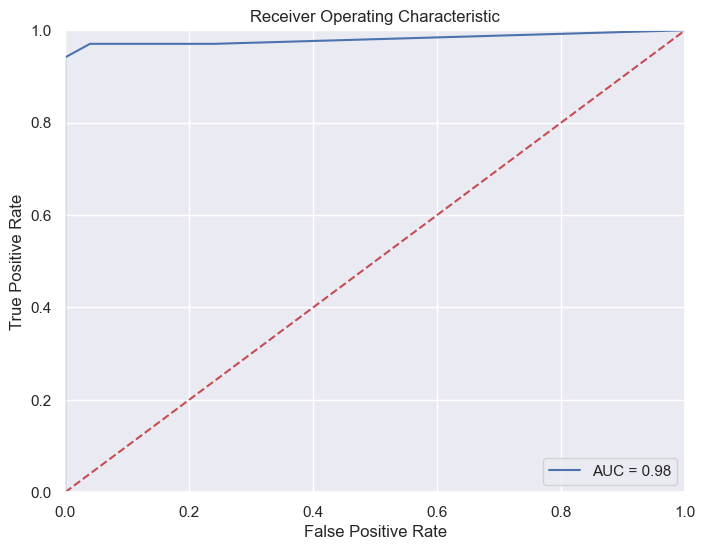

In [496]:
plot_roc(knn, x_test, y_test)